# Zadanie 2 - analiza jakości zdjęć na podstawie automatycznej oceny histogramu.

In [1]:
import cv2, numpy as np, requests
import matplotlib.pyplot as plt

/Users/jakubmajcher/Documents/Dok_WSB/semestr_3/Poplawski_kurs/lab2-obrazy/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Krok 1: wczytanie obrazu zdalnie
Zastosowanie listy `urls` do wczytania trzech zdjęć oraz wybór zdjęcia poprzez zmianę `nr`.

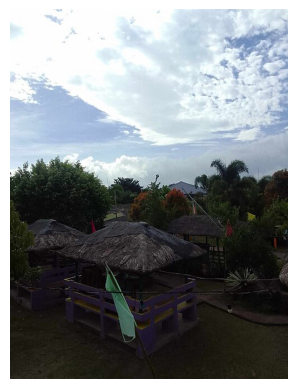

In [10]:
urls = [
    "https://thumb.wikimedia.org/wikipedia/commons/thumb/b/b8/Lemons_for_sale.JPG/960px-Lemons_for_sale.JPG?download",
    "https://thumb.wikimedia.org/wikipedia/commons/thumb/e/e0/It%27s_beautiful.jpg/500px-It%27s_beautiful.jpg?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=thumbnail",
    "https://upload.wikimedia.org/wikipedia/commons/1/16/Luz_en_el_horizonte_%283075390188%29.jpg?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=original"

]

def load_image(url):
    data = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).content
    img = cv2.cvtColor(cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    return img

imgs = [load_image(url) for url in urls]

# wybieranie obrazu do wyświetlenia (0 / 1 / 2)
nr = 1

img = imgs[nr]
plt.imshow(img); plt.axis('off'); plt.show()

# Krok 2: wyświetlanie histogramu dla całego zdjęcia oraz dla każdego z trzech kanałów

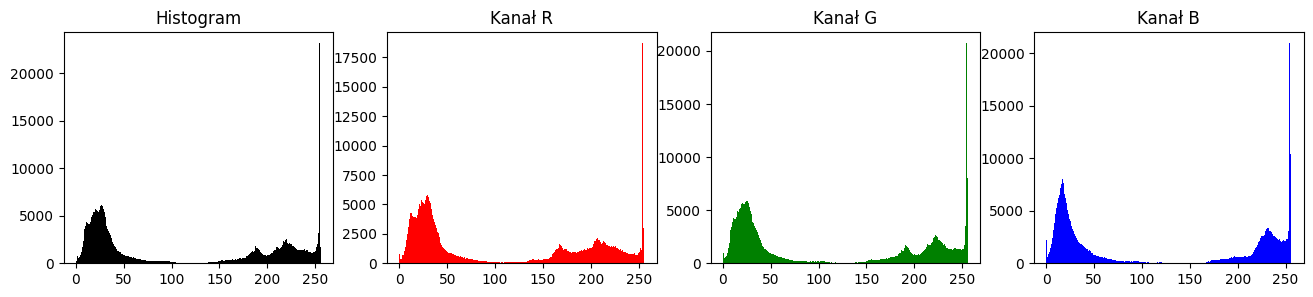

In [15]:
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
fig, ax = plt.subplots(1, 4, figsize=(16, 3))
ax[0].hist(gray.ravel(), bins = 256, range=(0, 256), color='k'); ax[0].set_title('Histogram')
for i, c in enumerate(['r', 'g', 'b']):
    ax[i+1].hist(img[:, :, i].ravel(), bins = 256, range=(0, 256), color=c); ax[i+1].set_title(f'Kanał {c.upper()}')
plt.show()

# Krok 3: szacunkowa ocena jakości zdjęcia i wypisanie potencjalnych problemów na podstawie histogramu

In [7]:
def validate(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    p1, p99 = np.percentile(g, [1, 99])
    problems = []
    if g.mean() < 85:
        problems.append("Obraz jest zbyt ciemny")
    if g.mean() > 170:
        problems.append("Obraz jest zbyt jasny")
    if p99 - p1 < 150:
        problems.append("Obraz ma zbyt mały kontrast")
    if (g < 6).mean() > 0.1:
        problems.append("Obraz ma zbyt dużo czarnych pikseli - przycięte cienie")
    if (g > 249).mean() > 0.1:
        problems.append("Obraz ma zbyt dużo białych pikseli - przycięte światła")
    return problems

problems = validate(img)
print("Problemy z obrazem:" if problems else "Brak problemów", problems)

Brak problemów []
